# Figure 3 Supplement 1: Stopping-model comparison and parameter recovery

Each alternative changes one part of the main stopping model and is fit to the
same trials (`scripts/run_stopping_fits.py`; one fit per subject, jointly over
that subject's six OL blocks, so the comparison uses all six blocks rather than
only the low-SNR blocks 1–3 shown in the other Figure 3 supplements).

- **A — total ΔAIC** (alternative − main, summed over subjects; positive =
  main model better), log scale.
- **B — per subject:** the fraction of subjects for whom the main model is
  better by more than 2 AIC units, the two are within 2, or the alternative is
  better by more than 2.
- **C, D — parameter recovery** (`scripts/run_stopping_bootstrap.py`): each OL
  subject was simulated `NUM_REPS` = 10 times from their main fit, on their
  real trial structure (same blocks, trial counts, SNRs and step statistics),
  and each simulated data set was refit with the same procedure. Each cell:
  Spearman correlation across subjects between the parameter used to simulate
  and the median of its 10 refits. **C:** parameters fit separately in each
  block (bound plateau, bound variability = CV of the trial-to-trial bound,
  guess, lapse and anticipation rates), OL low-SNR blocks 1–3; subject-blocks
  whose plateau sits at a fit limit are left out (counts printed). **D:**
  parameters shared across a subject's blocks (start height = bound at step 1
  relative to the plateau, log; time of the fall to the plateau; slope of the
  bound after the fall, log units per step; sensory noise; probability of a
  one-step non-decision time vs. two steps). Refits that did not converge are
  left out (counts printed). The table also gives each parameter's median
  per-subject spread of refits (10th–90th percentile, relative to the
  simulated value), used for error bars elsewhere.

Main model: the bound starts high, falls to a plateau at a time fit for each
subject, then declines slowly; this time course is the same in all of a
subject's blocks. The plateau, the bound's trial-to-trial variability and the
guess, lapse and anticipation rates are fit per block; sensory noise and the
non-decision time (1 or 2 steps) per subject.

Alternatives (fit variant in parentheses):

- **Constant bound** (`flat`): no time course.
- **Constant bound, more guessing early** (`flat_guess_tc`): instead of a high
  early bound, a guess rate that changes over the trial.
- **Bound falls at fixed times** (`knots`, the previous main model): the bound
  changes linearly between fixed steps 1, 6 and 16 instead of falling to its
  plateau at a fitted time.
- **No slow decline after the fall** (`knee_flat`): the bound stays at the
  plateau after the initial fall.
- **Separate bound time course per block** (`per_block_tc`) or **per SNR**
  (`tc_by_snr`).
- **No sensory noise** (`no_noise`).
- **Non-decision time up to 3 steps** (`ndt123`): the main model allows 1 or 2 steps
  (the key press 200–600 ms after the committed position appeared); this one also allows 3.
- **Same guess and lapse rates in all blocks** (`shared_rates`; anticipation
  rates also shared).

A variant with both a time-varying bound (fixed times) and a time-varying guess rate (`both_tc`) is in
Test_stoppingModel and not shown.

In [1]:
import sys
sys.path.insert(0, '..')

from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd
import scipy.stats

from pigeon.pathDefaults import FIGURES_DIR
from pigeon.plotting import FONT_RC, add_panel_label
from pigeon.stopping import get_plateau_at_limit

PROCESSED = Path('../data/processed')

In [2]:
TASK = 'OL'
AIC_MARGIN = 2.0
VARIANTS = {   # file suffix: label
    'flat': 'Constant bound',
    'flat_guess_tc': 'Constant bound, more guessing early',
    'knots': 'Bound falls at fixed times',
    'knee_flat': 'No slow decline after the fall',
    'per_block_tc': 'Separate bound time course per block',
    'tc_by_snr': 'Separate bound time course per SNR',
    'no_noise': 'No sensory noise',
    'ndt123': 'Non-decision time up to 3 steps',
    'shared_rates': 'Same guess and lapse rates in all blocks',
}

def _per_subject(variant):
    f = pd.read_pickle(PROCESSED / f'stopping_fits_{variant}.pkl')
    s = f[f.task == TASK].groupby('subject_index').first()
    return pd.DataFrame({'aic': 2 * s.nll + 2 * s.n_params, 'n_params': s.n_params, 'success': s.success})

main = _per_subject('main')
rows = []
for v, label in VARIANTS.items():
    alt = _per_subject(v)
    d = (alt.aic - main.aic).dropna()
    rows.append({'variant': v, 'label': label, 'subjects': len(d), 'ΔAIC total': d.sum(), 'ΔAIC median': d.median(),
                 'Δ params / subject': int((alt.n_params - main.n_params).median()),
                 'main better': np.mean(d > AIC_MARGIN), 'within 2': np.mean(d.abs() <= AIC_MARGIN),
                 'alternative better': np.mean(d < -AIC_MARGIN),
                 'not converged (alt / main)': f'{int((~alt.success).sum())} / {int((~main.success).sum())}'})
comp = pd.DataFrame(rows).set_index('variant')
display(comp.round(3))

,label,subjects,ΔAIC total,ΔAIC median,Δ params / subject,main better,within 2,alternative better,not converged (alt / main)
variant,,,,,,,,,
flat,Constant bound,60,4628.912,67.094,-3,0.967,0.033,0.000,0 / 0
flat_guess_tc,"Constant bound, more guessing early",60,3802.561,49.956,-1,0.967,0.000,0.033,0 / 0
knots,Bound falls at fixed times,60,1258.889,11.388,-1,0.733,0.217,0.050,0 / 0
knee_flat,No slow decline after the fall,60,529.618,4.639,-1,0.633,0.283,0.083,1 / 0
per_block_tc,Separate bound time course per block,60,1154.073,21.846,15,0.950,0.033,0.017,0 / 0
tc_by_snr,Separate bound time course per SNR,60,75.753,3.517,3,0.633,0.100,0.267,0 / 0
no_noise,No sensory noise,60,1345.207,13.571,-1,0.800,0.100,0.100,0 / 0
ndt123,Non-decision time up to 3 steps,60,316.648,6.455,1,0.600,0.217,0.183,0 / 0
shared_rates,Same guess and lapse rates in all blocks,60,13613.037,68.322,-15,0.733,0.050,0.217,1 / 0


In [3]:
BLOCKS = ['B1', 'B2', 'B3']
BLOCK_TITLES = {'B1': 'No penalty', 'B2': 'Coin penalty', 'B3': 'Step penalty'}
PER_BLOCK = {'bound_scale': 'Bound plateau', 'bound_cv': 'Bound variability', 'guess_rate': 'Guess rate',
             'lapse_rate': 'Lapse rate', 'anticipation_rate': 'Anticipation rate'}
SHARED = {'log_h_start': 'Start height', 'knee': 'Time of fall', 'late_slope': 'Slope after the fall',
          'sensory_std': 'Sensory noise', 'ndt_p1': 'P(1-step non-decision time)'}

boot = pd.read_pickle(PROCESSED / 'stopping_bootstrap.pkl')
boot = boot[boot.task == 'OL']
n_fail = boot[~boot.success].groupby(['subject_index', 'rep']).ngroups
print(f'{n_fail} of {boot.groupby(["subject_index", "rep"]).ngroups} OL refits did not converge (left out)')
boot = boot[boot.success]
true = boot.groupby(['subject_index', 'group']).first()[[f'{p}_true' for p in {**PER_BLOCK, **SHARED}]]
fit = boot.groupby(['subject_index', 'group'])[[f'{p}_fit' for p in {**PER_BLOCK, **SHARED}]]
med, q10, q90 = fit.median(), fit.quantile(0.1), fit.quantile(0.9)

lim = pd.DataFrame({'bound_scale': true.bound_scale_true, 'group': true.index.get_level_values('group'),
                    'subject_index': true.index.get_level_values('subject_index')})
l_lim = get_plateau_at_limit(lim).to_numpy() & true.index.get_level_values('group').isin(BLOCKS)
print(f'per-block parameters: left out {int(l_lim.sum())} subject-blocks with the plateau at a fit limit: '
      f'{list(true.index[l_lim])}')

def _rho(t, m):
    ok = np.isfinite(t) & np.isfinite(m)
    return scipy.stats.spearmanr(t[ok], m[ok]).statistic, int(ok.sum())

def _spread(t, lo, hi):
    return np.median((hi - lo) / np.abs(t))

rows, rho_block = [], pd.DataFrame(index=list(PER_BLOCK), columns=BLOCKS, dtype=float)
for p, label in PER_BLOCK.items():
    for b in BLOCKS:
        l = (true.index.get_level_values('group') == b) & ~l_lim
        r, n = _rho(true.loc[l, f'{p}_true'], med.loc[l, f'{p}_fit'])
        rho_block.loc[p, b] = r
        rows.append({'parameter': label, 'block': b, 'subjects': n, 'Spearman rho': r,
                     'median relative 10-90% spread': _spread(true.loc[l, f'{p}_true'], q10.loc[l, f'{p}_fit'],
                                                              q90.loc[l, f'{p}_fit'])})
first = true.groupby(level='subject_index').head(1).index    # shared parameters: one row per subject
rho_shared = pd.Series(index=list(SHARED), dtype=float)
for p, label in SHARED.items():
    r, n = _rho(true.loc[first, f'{p}_true'], med.loc[first, f'{p}_fit'])
    rho_shared[p] = r
    rows.append({'parameter': label, 'block': 'all', 'subjects': n, 'Spearman rho': r,
                 'median relative 10-90% spread': _spread(true.loc[first, f'{p}_true'], q10.loc[first, f'{p}_fit'],
                                                          q90.loc[first, f'{p}_fit'])})
display(pd.DataFrame(rows).round(3))

0 of 600 OL refits did not converge (left out)
per-block parameters: left out 5 subject-blocks with the plateau at a fit limit: [(13, 'B3'), (44, 'B3'), (51, 'B1'), (51, 'B2'), (59, 'B1')]


,parameter,block,subjects,Spearman rho,median relative 10-90% spread
0,Bound plateau,B1,58,0.992,0.273
1,Bound plateau,B2,59,0.994,0.199
2,Bound plateau,B3,57,0.886,0.266
3,Bound variability,B1,58,0.962,0.702
4,Bound variability,B2,59,0.974,0.517
5,Bound variability,B3,57,0.957,0.665
6,Guess rate,B1,58,0.991,0.730
7,Guess rate,B2,59,0.978,1.302
8,Guess rate,B3,57,0.943,2.353
9,Lapse rate,B1,58,0.968,1.370


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


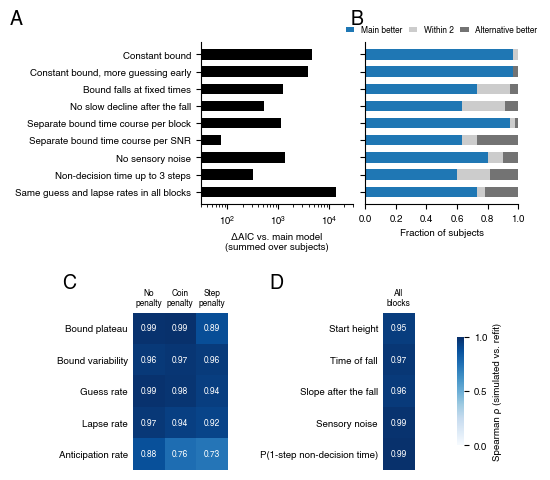

Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Figures/Figure03_S01.pdf (+ .png)


In [4]:
CM = 1 / 2.54
FS = 7
plt.rcParams.update({'font.size': FS, 'axes.labelsize': FS, 'axes.titlesize': FS, **FONT_RC})
MODEL = 'tab:blue'

yy = np.arange(len(VARIANTS))

fig = plt.figure(figsize=(13 * CM, 12.5 * CM))
gs_top = gridspec.GridSpec(1, 2, figure=fig, wspace=0.08, left=0.36, right=0.98, bottom=0.6, top=0.93)
ax_a, ax_b = fig.add_subplot(gs_top[0]), fig.add_subplot(gs_top[1])
gs_bot = gridspec.GridSpec(1, 2, figure=fig, width_ratios=[3, 1], wspace=2.2, left=0.22, right=0.78, bottom=0.06,
                           top=0.38)
ax_c, ax_d = fig.add_subplot(gs_bot[0]), fig.add_subplot(gs_bot[1])

ax_a.barh(yy, comp['ΔAIC total'], color='k', height=0.6)
ax_a.set_xscale('log')
ax_a.set_xlim(30, 3e4)
ax_a.set_yticks(yy)
ax_a.set_yticklabels(list(VARIANTS.values()))
ax_a.invert_yaxis()
ax_a.set_xlabel('ΔAIC vs. main model\n(summed over subjects)')

left = np.zeros(len(VARIANTS))
for col, color in (('main better', MODEL), ('within 2', '0.8'), ('alternative better', '0.45')):
    w = comp[col].to_numpy()
    ax_b.barh(yy, w, left=left, color=color, height=0.6, label=col.capitalize())
    left += w
ax_b.set_xlim(0, 1)
ax_b.set_yticks(yy)
ax_b.set_yticklabels([])
ax_b.invert_yaxis()
ax_b.set_xlabel('Fraction of subjects')
ax_b.legend(fontsize=6, frameon=False, loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=3,
            handlelength=1, columnspacing=0.8)

for ax in (ax_a, ax_b):
    ax.spines[['top', 'right']].set_visible(False)
CMAP = 'Blues'

def _heatmap(ax, values, ylabels, xlabels):
    im = ax.imshow(values, cmap=CMAP, vmin=0, vmax=1, aspect='equal')
    for (i, j), v in np.ndenumerate(values):
        ax.text(j, i, f'{v:.2f}'.replace('-', '\u2212'), ha='center', va='center', fontsize=6,
                color='w' if v > 0.6 else 'k')
    ax.set_yticks(range(len(ylabels)), ylabels)
    ax.set_xticks(range(len(xlabels)), xlabels, fontsize=6)
    ax.xaxis.tick_top()
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    return im

_heatmap(ax_c, rho_block.to_numpy(), list(PER_BLOCK.values()), [BLOCK_TITLES[b].replace(' ', '\n') for b in BLOCKS])
im = _heatmap(ax_d, rho_shared.to_numpy()[:, None], list(SHARED.values()), ['All\nblocks'])
fig.canvas.draw()
pos = ax_d.get_position()
cax = fig.add_axes([0.86, pos.y0 + 0.05, 0.015, pos.height - 0.1])
cb = fig.colorbar(im, cax=cax, ticks=[0, 0.5, 1])
cb.set_label('Spearman ρ (simulated vs. refit)')
cb.outline.set_visible(False)
add_panel_label(ax_a, 'A', dx=-1.25, dy=1.2)
add_panel_label(ax_b, 'B', dx=-0.1, dy=1.2)
add_panel_label(ax_c, 'C', dx=-0.75, dy=1.25)
add_panel_label(ax_d, 'D', dx=-3.6, dy=1.25)

out = FIGURES_DIR / 'Figure03_S01.pdf'
fig.savefig(out, dpi=300, bbox_inches='tight')
fig.savefig(out.with_suffix('.png'), dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {out} (+ .png)')

## Interpretation

(Filled in after review.)